In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.feature_selection import RFECV
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from hyperopt import STATUS_OK, Trials, fmin, hp, tpe

In [2]:
# Scarichiamo e leggiamo i dati del train.csv file
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

# droppiamo le colonne che non ci servono
PCIAT_cols = [col for col in df.columns if 'PCIAT' in col]
df = df.drop(PCIAT_cols, axis=1)
df = df.drop(columns=['id'])

Valori da predire: [ 2.  0.  1. nan  3.]
Valori nulli nella colonna target: 1224
Tipo della classe target: float64
Valori nulli nella colonna target dopo il drop: 0


In [4]:
#                     #
# Feature Engineering #
#                     #

df = df[df['Physical-Weight'] != 0]

# Prendiamo la media tra i valori di BMI
df['Physical-BMI'] = df[['Physical-BMI', 'BIA-BIA_BMI']].mean(axis=1)
df = df.drop(columns=['BIA-BIA_BMI'], axis=1)

df_with_cat_and_na = df.copy()

# Codifichiamo le varibili stagionali (10 features -> one-hot aggiungerebbe troppe colonne)
season_cols = [col for col in df.columns if 'Season' in col]
# season_mapping = {
#     "Summer": 0,
#     "Fall": 1,
#     "Winter": 2,
#     "Spring": 3,
# }

# for col in season_cols:
#     df[col] = df[col].map(season_mapping)
df = pd.get_dummies(df, columns=season_cols, drop_first=False)

In [5]:
# Elimino le colonne che hanno più del 50% di valori mancanti e che non sono molto correlate con la variabile target
missing_percentage = df.isnull().mean()
columns_to_drop = missing_percentage[missing_percentage > 0.5].index
print(f"Colonne con 50%+ valori mancanti: {list(columns_to_drop)}")

correlation_with_target = df[columns_to_drop].corrwith(df['sii']).abs().sort_values(ascending=False)
print("Correlazione con la variabile target:")
print(correlation_with_target)

high_corr_features = correlation_with_target[correlation_with_target > 0.10].index  
columns_to_really_drop = set(columns_to_drop) - set(high_corr_features)

print(f"Colonne salvate: {list(high_corr_features)}")
df = df.drop(columns=columns_to_really_drop)

Colonne con 50%+ valori mancanti: ['Physical-Waist_Circumference', 'Fitness_Endurance-Max_Stage', 'Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec', 'FGC-FGC_GSND', 'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'PAQ_A-PAQ_A_Total']
Correlazione con la variabile target:
Physical-Waist_Circumference    0.272885
FGC-FGC_GSD                     0.163448
FGC-FGC_GSND                    0.149495
Fitness_Endurance-Max_Stage     0.070589
Fitness_Endurance-Time_Mins     0.060628
PAQ_A-PAQ_A_Total               0.045968
FGC-FGC_GSD_Zone                0.023696
Fitness_Endurance-Time_Sec      0.008701
FGC-FGC_GSND_Zone               0.001667
dtype: float64
Colonne salvate: ['Physical-Waist_Circumference', 'FGC-FGC_GSD', 'FGC-FGC_GSND']


In [6]:
df_with_na = df.copy()
for col in df.columns:
   df[col].fillna(round(df[col].mean()), inplace=True)

df = df.astype(float)
df = df.round(2)

/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_14291/1670664959.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(round(df[col].mean()), inplace=True)


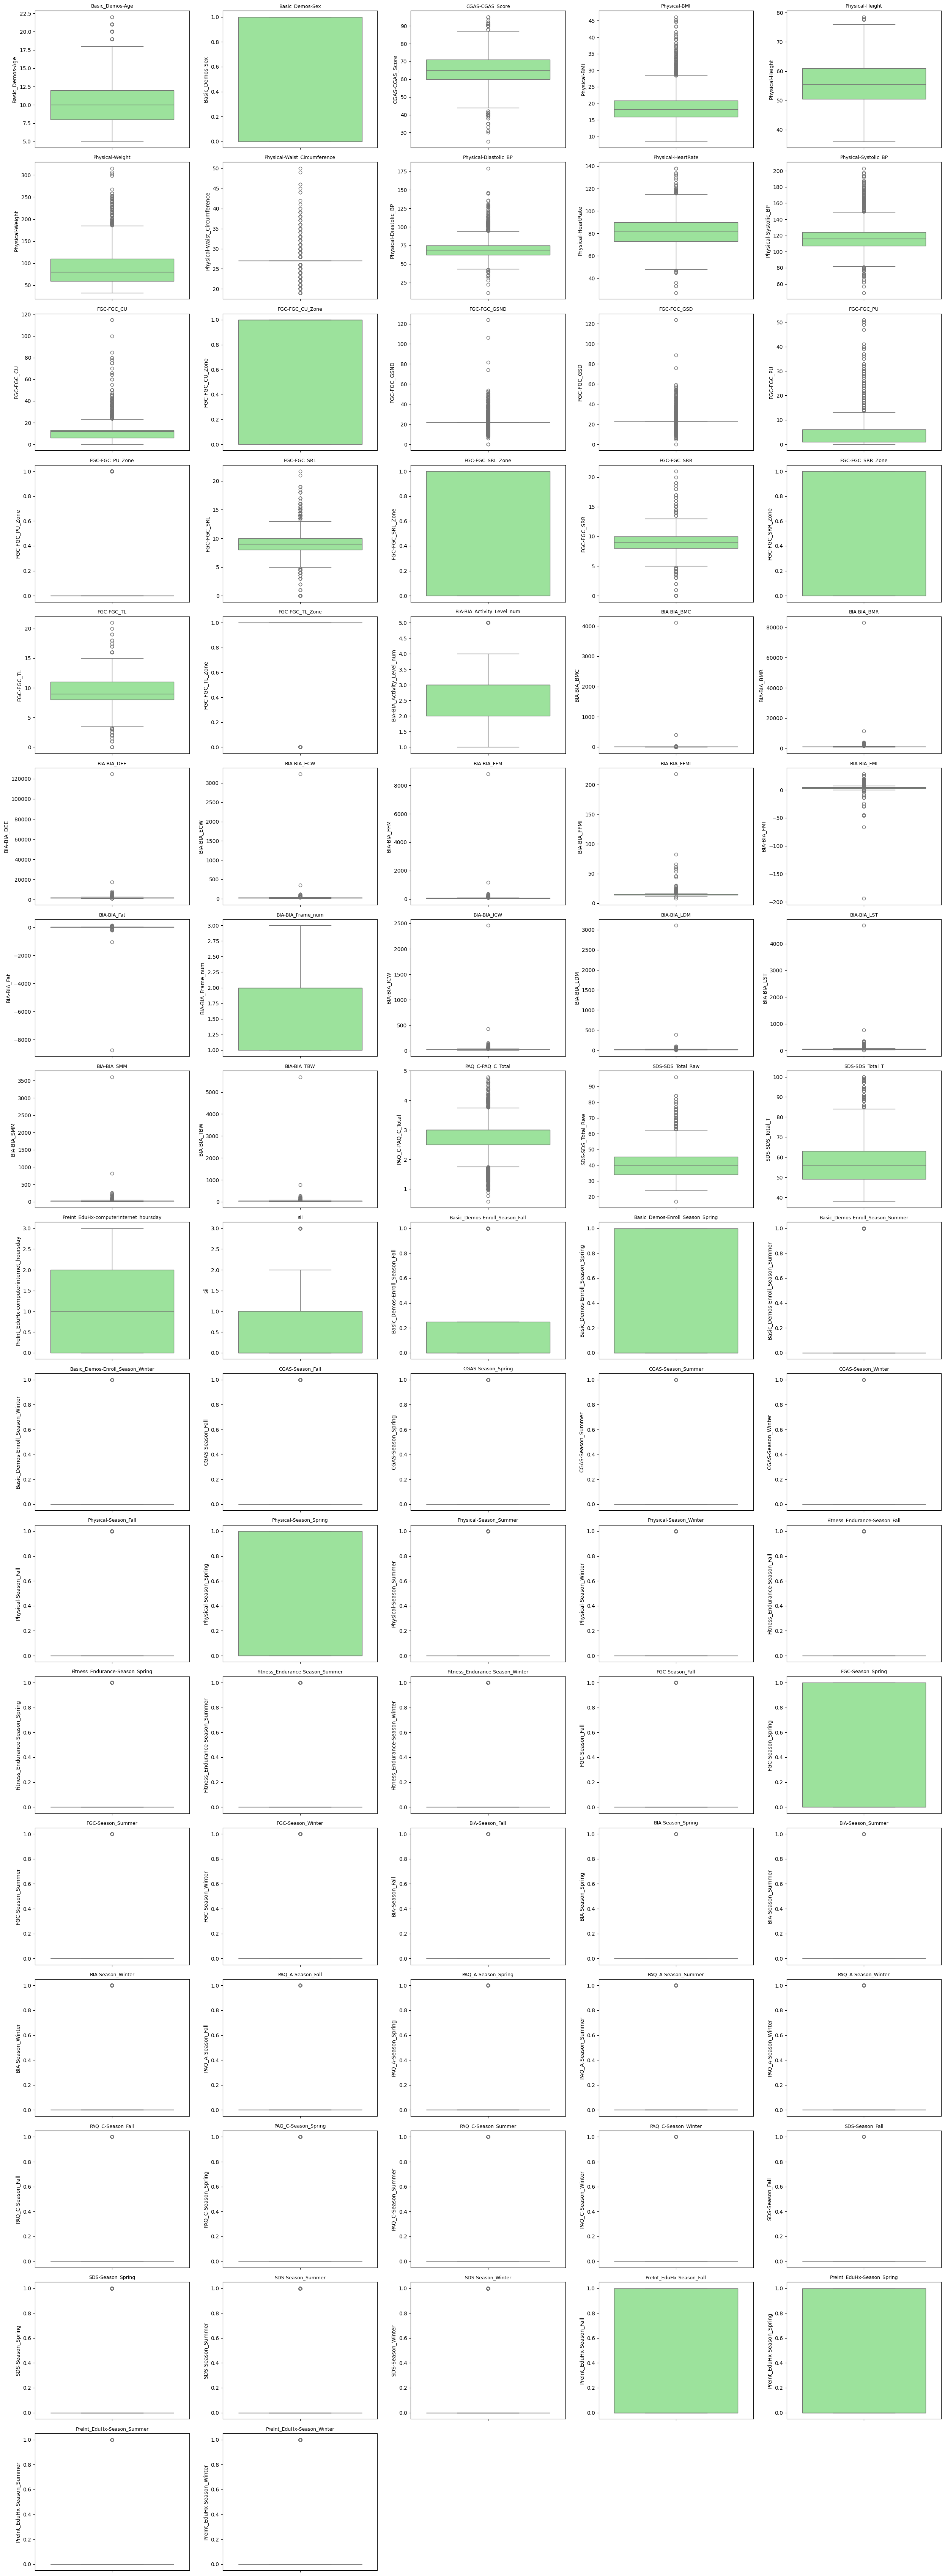

In [7]:
n_cols = len(df.columns)

# Imposta il numero di colonne per riga
cols_per_row = 5
n_rows = math.ceil(n_cols / cols_per_row)
plt.figure(figsize=(5 * cols_per_row, 4 * n_rows))

# Crea i boxplot
for i, col in enumerate(df.columns, 1):
    plt.subplot(n_rows, cols_per_row, i)
    sns.boxplot(y=df[col], color="lightgreen")
    plt.title(col, fontsize=9)
    plt.tight_layout()

plt.show()


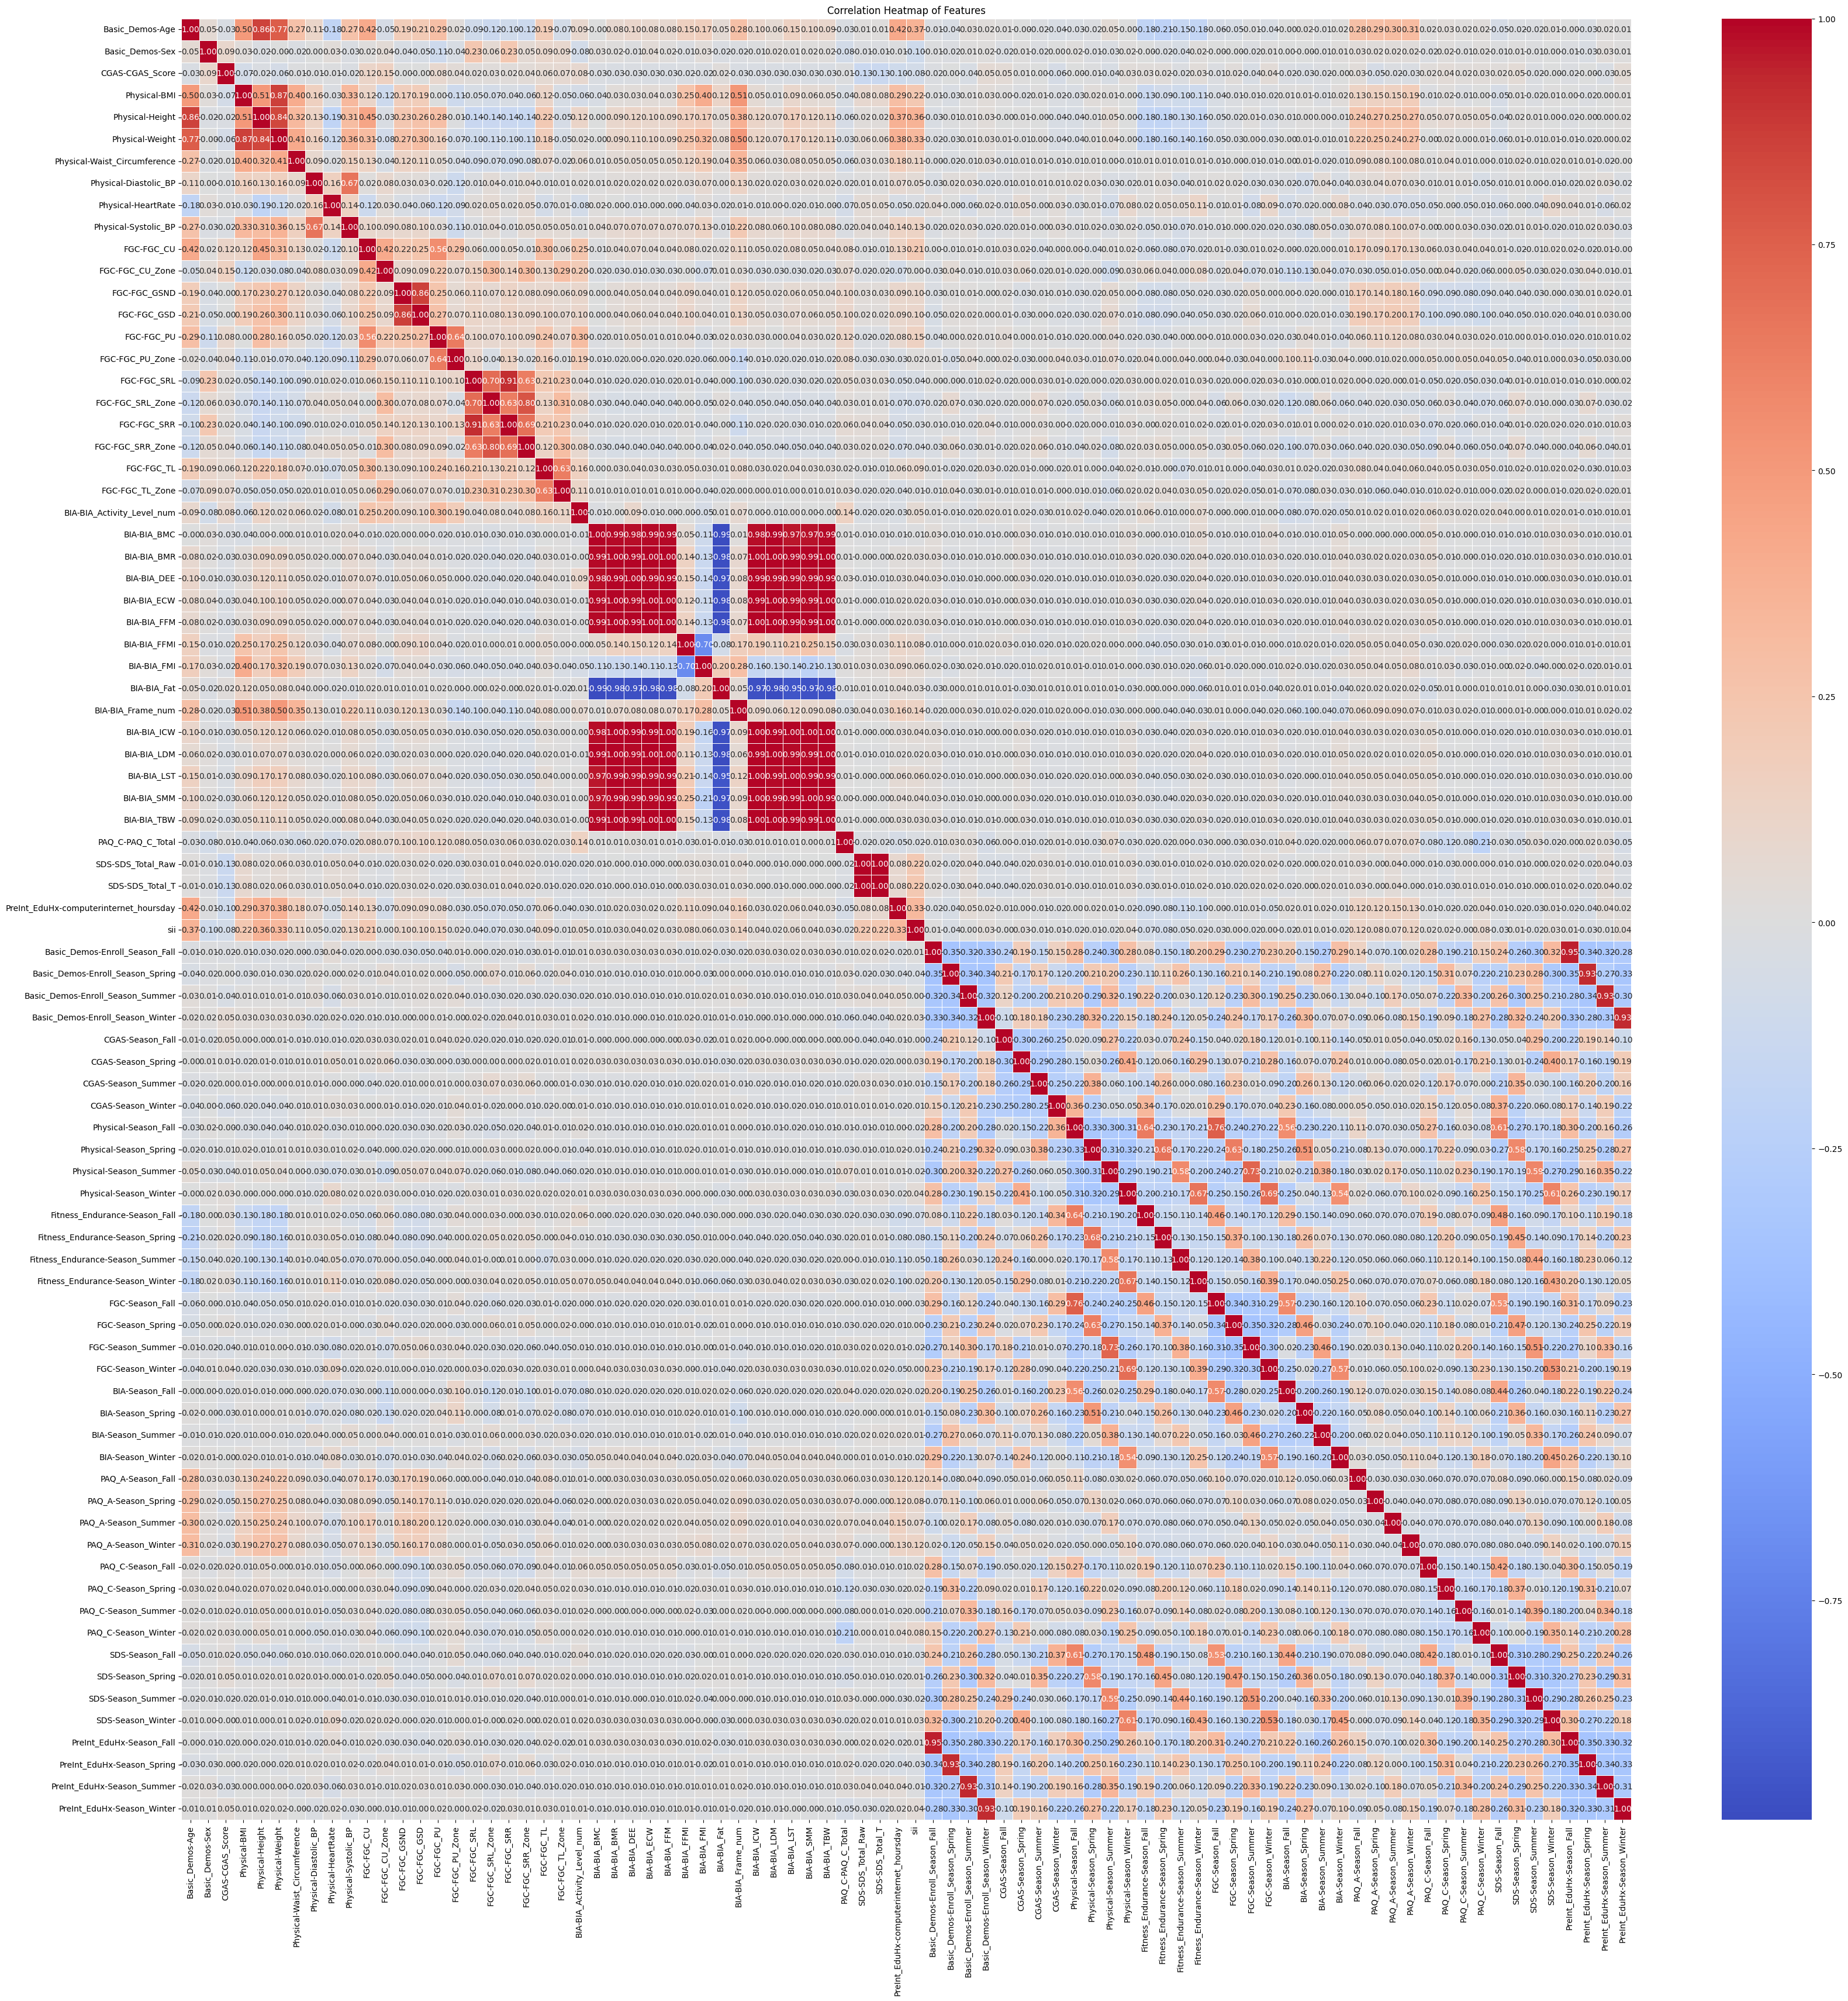

In [8]:
corr_matrix = df.corr()

plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [9]:
X = df.drop(columns=['sii'])
y = df['sii']

max_values = df.max()
min_values = df.min()

# Crea un nuovo DataFrame con i valori massimi e minimi
df_min_max = pd.DataFrame({
    'Colonna': df.columns,
    'Valore Minimo': min_values,
    'Valore Massimo': max_values
})

df_min_max

,Colonna,Valore Minimo,Valore Massimo
Basic_Demos-Age,Basic_Demos-Age,5.00,22.00
Basic_Demos-Sex,Basic_Demos-Sex,0.00,1.00
CGAS-CGAS_Score,CGAS-CGAS_Score,25.00,95.00
Physical-BMI,Physical-BMI,8.51,46.11
Physical-Height,Physical-Height,36.00,78.50
...,...,...,...
SDS-Season_Winter,SDS-Season_Winter,0.00,1.00
PreInt_EduHx-Season_Fall,PreInt_EduHx-Season_Fall,0.00,1.00
PreInt_EduHx-Season_Spring,PreInt_EduHx-Season_Spring,0.00,1.00
PreInt_EduHx-Season_Summer,PreInt_EduHx-Season_Summer,0.00,1.00


Feature 'Physical-Height' è fortemente correlata con: ['Basic_Demos-Age'], eliminata.
Feature 'Physical-Weight' è fortemente correlata con: ['Basic_Demos-Age', 'Physical-BMI'], eliminata.
Feature 'FGC-FGC_GSD' è fortemente correlata con: ['FGC-FGC_GSND'], eliminata.
Feature 'FGC-FGC_SRR' è fortemente correlata con: ['FGC-FGC_SRL'], eliminata.
Feature 'FGC-FGC_SRR_Zone' è fortemente correlata con: ['FGC-FGC_SRL_Zone'], eliminata.
Feature 'BIA-BIA_BMR' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_DEE' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ECW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_FFM' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_Fat' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ICW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_LDM' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_LST'

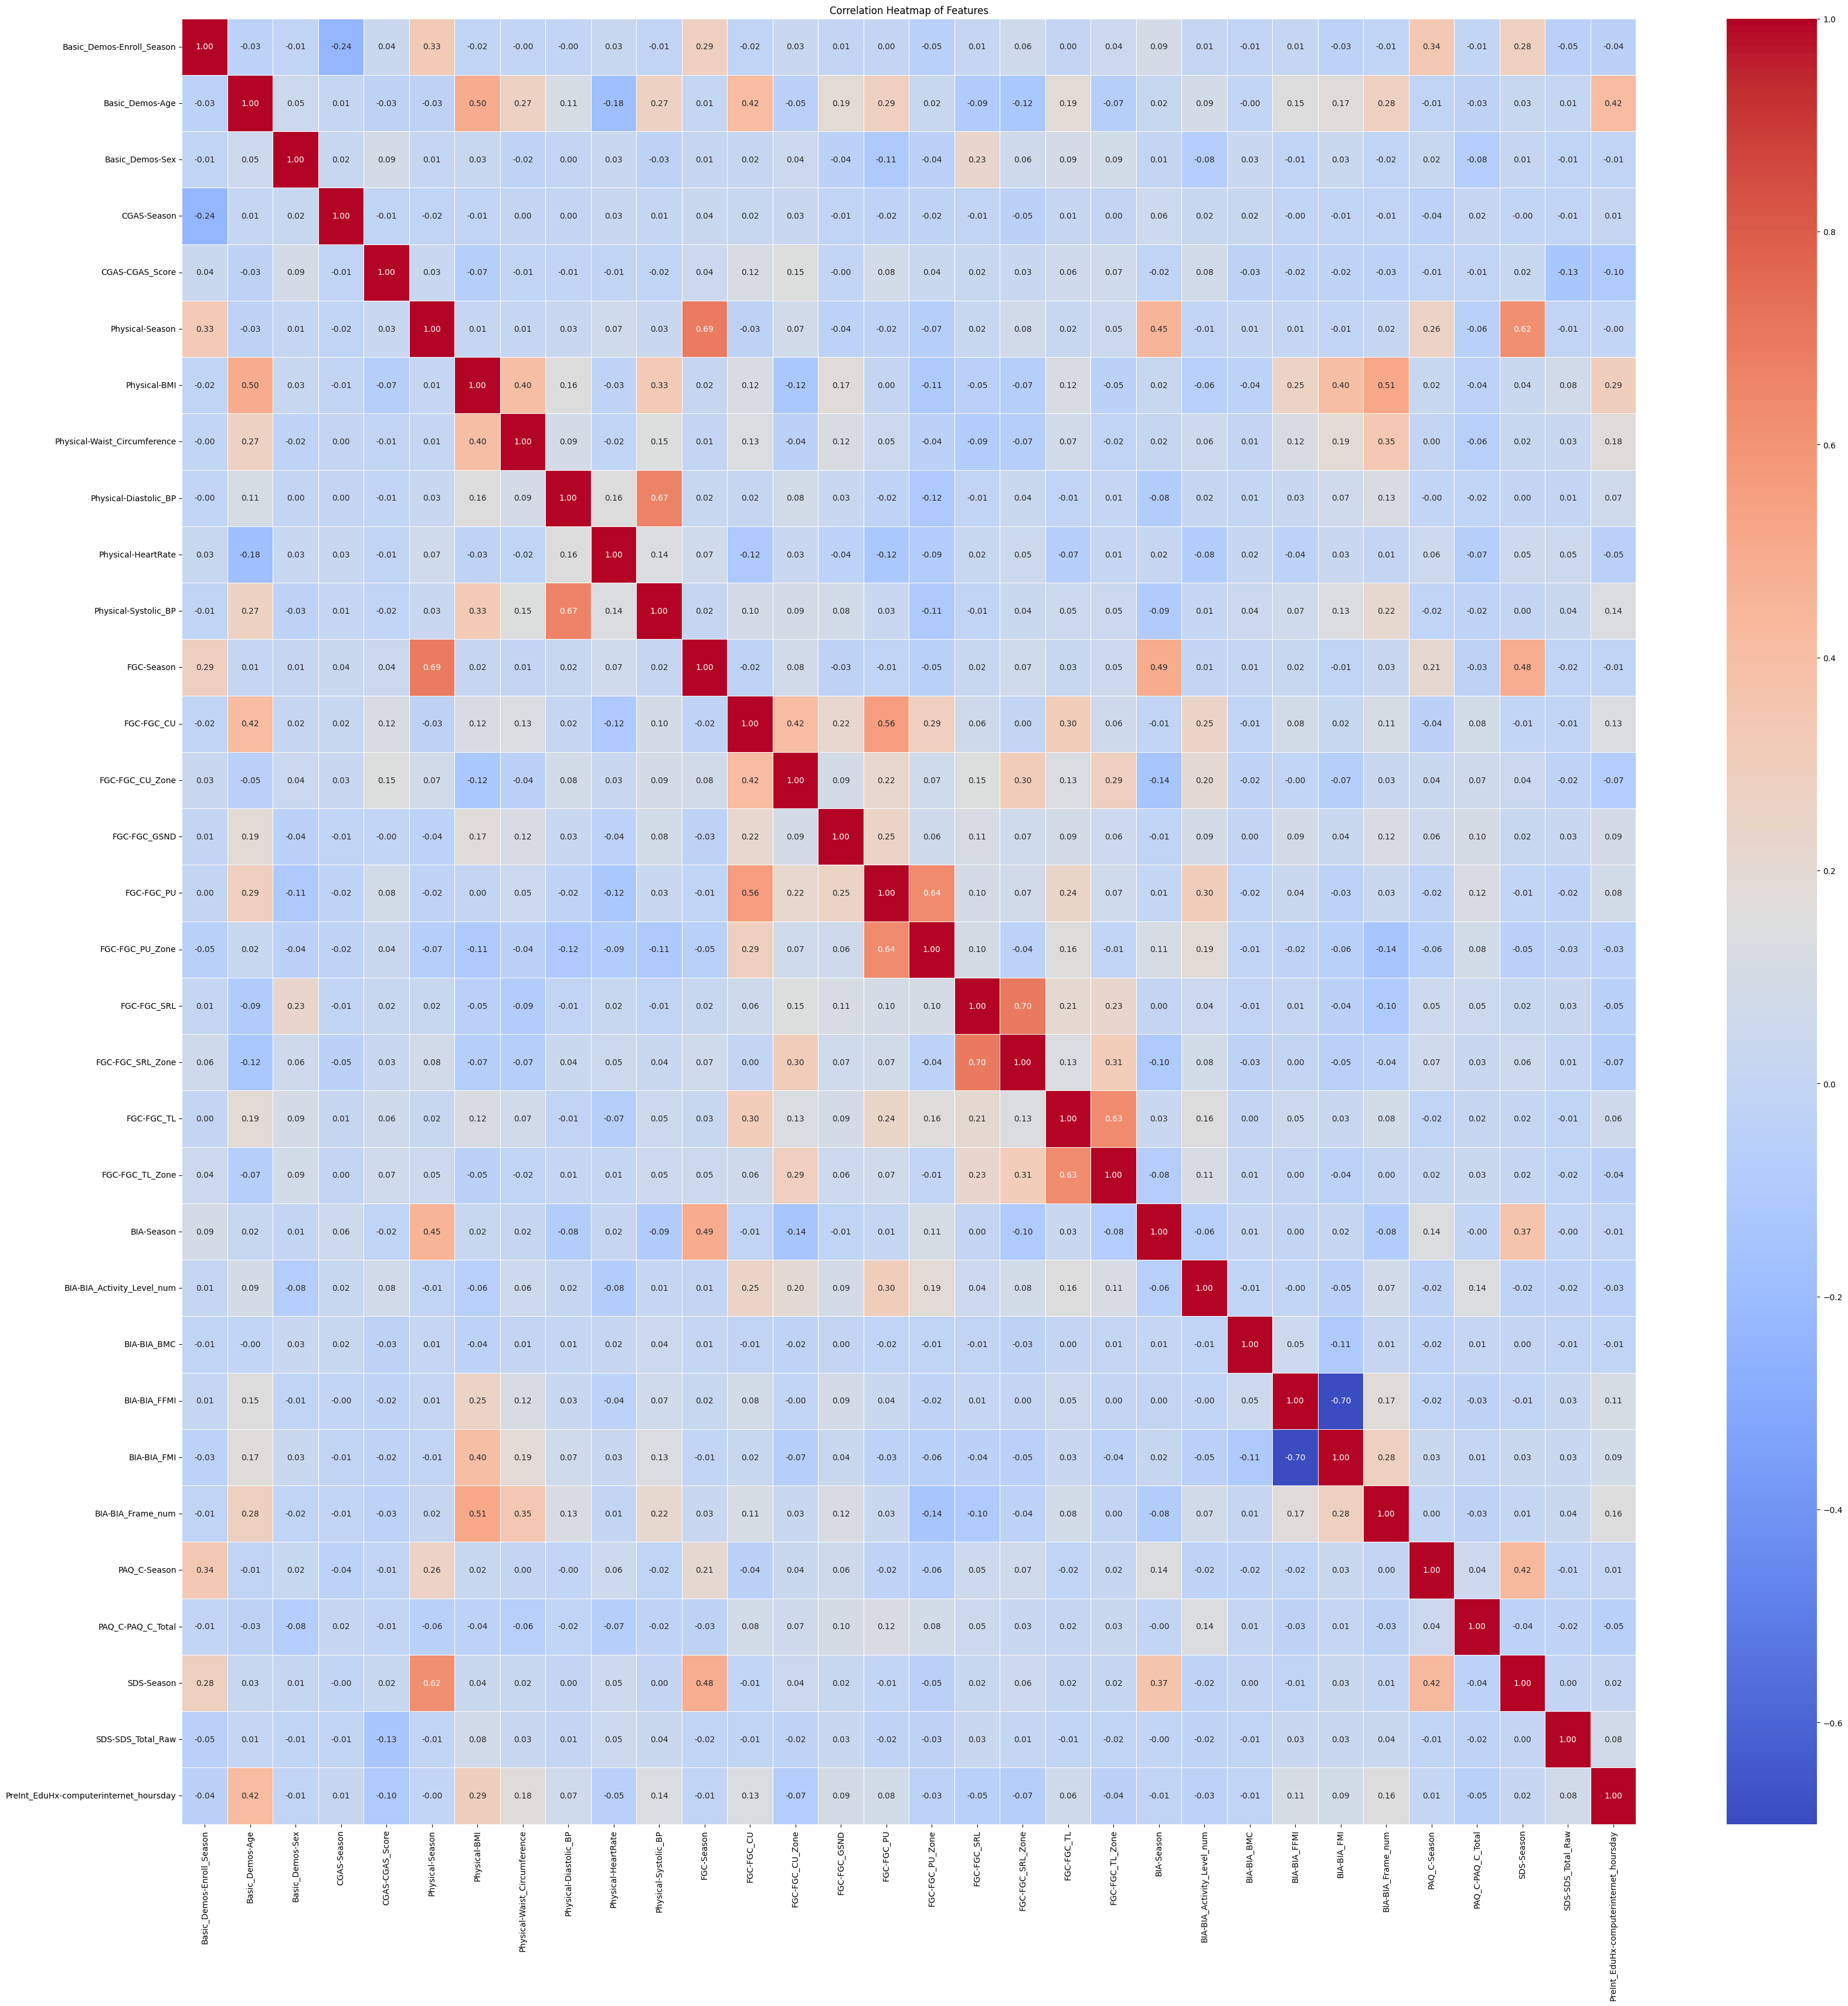

In [ ]:
# Droppiamo le feature con una correlazione > di 0.7 o < di -0.7 -> Troppo correlate tra loro
threshold = 0.7

while True:
    corr_matrix = X.corr()  # Ricalcola la matrice di correlazione
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = None
    for column in upper.columns:
        if any(abs(upper[column]) >= threshold):
            to_drop = column
            break  # Esci dal ciclo appena trovi una feature da eliminare

    if to_drop is None:
        break  # Se non ci sono più feature da eliminare, esci dal ciclo

    correlated_features = upper.index[abs(upper[to_drop]) >= threshold].tolist()
    print(f"Feature '{to_drop}' è fortemente correlata con: {correlated_features}, eliminata.")

    X = X.drop(columns=to_drop)

print(f"Dropped features: {to_drop}")
X.shape

corr_matrix = X.corr()

plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [171]:
print("X shape", X.shape)
print("y shape", y.shape)

# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
print(y.value_counts(normalize=True))

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)


X shape (2684, 81)
y shape (2684,)
sii
0.0    0.581222
1.0    0.267511
2.0    0.138599
3.0    0.012668
Name: proportion, dtype: float64


In [172]:
# Proviamo con un albero di decisione con tutti i parametri di default
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train80,y_train80)

print("Train acc:", accuracy_score(y_true = y_train80, y_pred = dt.predict(X_train80)))
print("Test acc:", accuracy_score(y_true = y_test20,  y_pred = dt.predict(X_test20)))

scores = cross_val_score(dt, X_train80, y_train80, cv=20)
print("Accuracy media con cv=20:", scores.mean())

Train acc: 1.0
Test acc: 0.5046554934823091
Accuracy media con cv=20: 0.4862712011076497


In [93]:
#
# Modello usando un albero di decisione
# usando come stopping criteria il numero di foglie
# split: 80/20
#

best_leaves = None
best_cv_acc = 0
for max_leaves in range(2,30):
    dt = DecisionTreeClassifier(max_leaf_nodes=max_leaves, random_state=42)
    cv_scores = cross_val_score(dt, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        best_leaves = max_leaves

print(f"Il miglior numero di foglie è {best_leaves} con una cross-validation accuracy di {best_cv_acc:.3f}")

Il miglior numero di foglie è 5 con una cross-validation accuracy di 0.608


In [94]:
#
# Modello usando un albero di decisione
# usando come stopping criteria la profondità
# split: 80/20
#

bestDepth = None
best_cv_acc = 0
for max_depth in range(1, 20):
    dt = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    cv_scores = cross_val_score(dt, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        bestDepth = max_depth

print(f"Il miglior numero di profondità è {bestDepth} con una cross-validation accuracy di {best_cv_acc:.3f}")

Il miglior numero di profondità è 3 con una cross-validation accuracy di 0.604


In [173]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'min_samples_leaf': [10, 25, 50, 100, 150],
    # 'min_impurity_decrease': [0.0, 0.001, 0.003, 0.005, 0.007, 0.01],
    'max_depth': [3, 5, 7, 10],
}

dt = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=20, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train80, y_train80)
print("Best parameters:", grid_search.best_params_)

print(grid_search.best_estimator_)
tuned_dt = grid_search.best_estimator_
tuned_dt.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_dt.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_dt.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_dt, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_dt.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 100}
DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=100,
                       random_state=42)
Train Accuracy: 0.619
Test Accuracy: 0.598
Cross-Validation Accuracy: 0.6148 ± 0.0319
Basic_Demos-Age                           0.463488
PreInt_EduHx-computerinternet_hoursday    0.232559
SDS-SDS_Total_T                           0.077417
SDS-SDS_Total_Raw                         0.039871
FGC-FGC_GSND                              0.038362
FGC-FGC_PU                                0.032889
Physical-Weight                           0.028111
Physical-Height                           0.023170
BIA-BIA_SMM                               0.022364
FGC-FGC_CU                                0.017837
dtype: float64


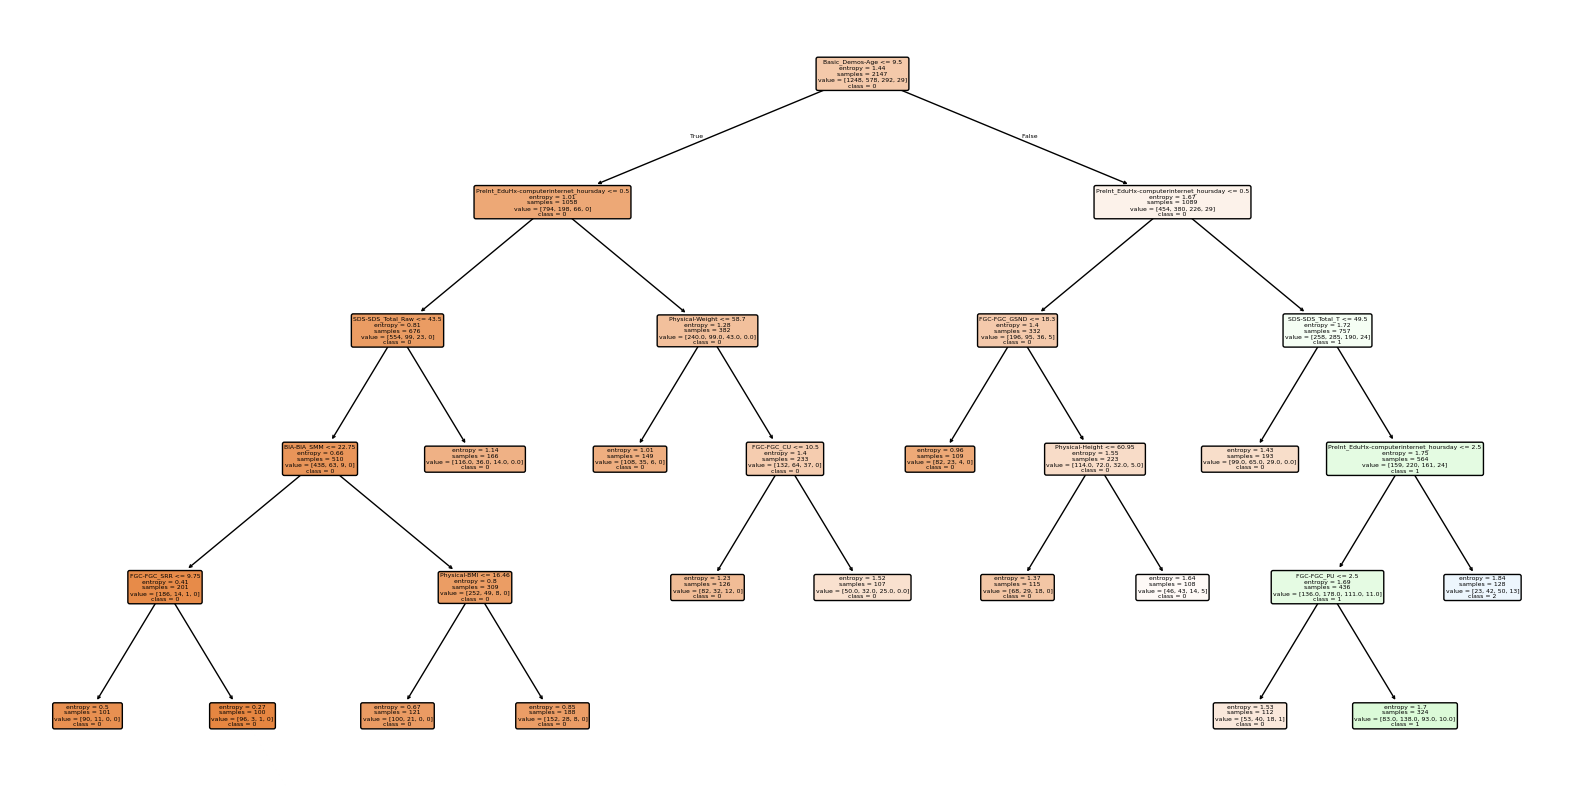

In [174]:
plt.figure(figsize=(20, 10)) 
plot_tree(tuned_dt, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], 
          rounded=True, proportion=False, precision=2)
plt.show()


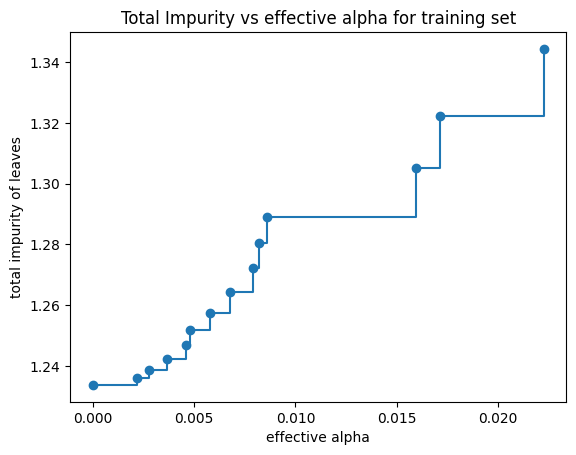

In [175]:
#
# Proviamo a fare pruning usando cross-validation
#

path = tuned_dt.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

In [176]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
best_params_grid = grid_search.best_params_
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        **best_params_grid,
        ccp_alpha=ccp_alpha,
        random_state=42
    )
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))

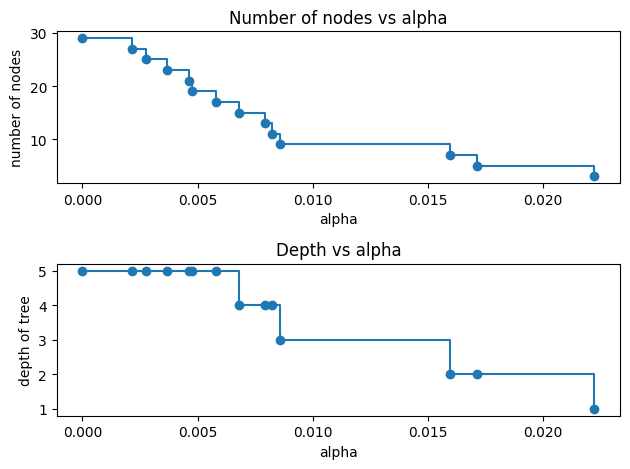

In [177]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

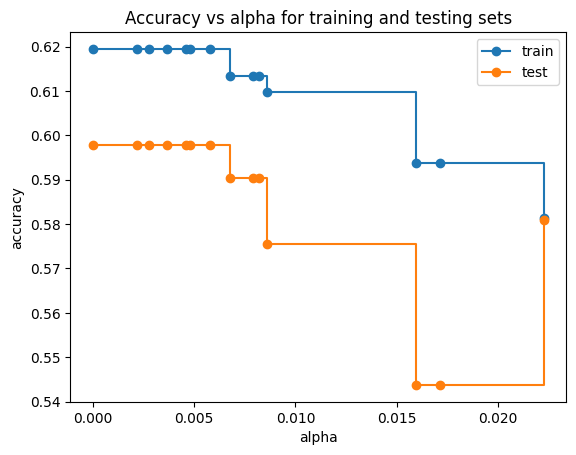

In [178]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

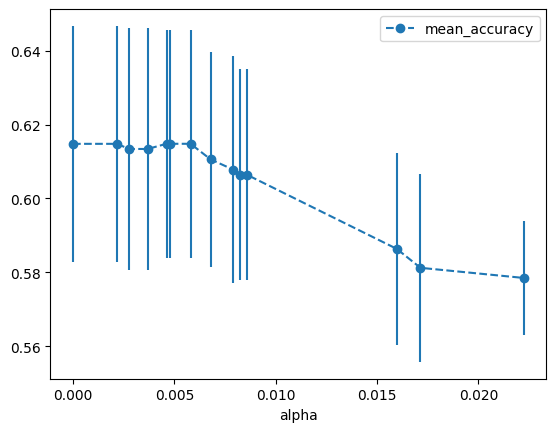

In [179]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        **best_params_grid,
        ccp_alpha=ccp_alpha,
        random_state=42,
    )
    scores = cross_val_score(dt, X_train80, y_train80, cv=20)
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])

alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [180]:
# prendo il valore di alpha che ha la media più alta con cv
subset = alpha_results[(alpha_results['alpha'] >= 0.0) 
              & (alpha_results['alpha'] < 0.010)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.00461291374398512


In [181]:
#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

pruned_dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ideal_alpha,
        **best_params_grid
    )
pruned_dt.fit(X_train80, y_train80)
print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=pruned_dt.predict(X_train80)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=pruned_dt.predict(X_test20)))

cv_scores = cross_val_score(pruned_dt, X_train80, y_train80, cv=20, scoring="accuracy")

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train accuracy: 0.6194690265486725
Test accuracy: 0.5977653631284916
Cross-Validation Accuracy: 0.6148 ± 0.0309


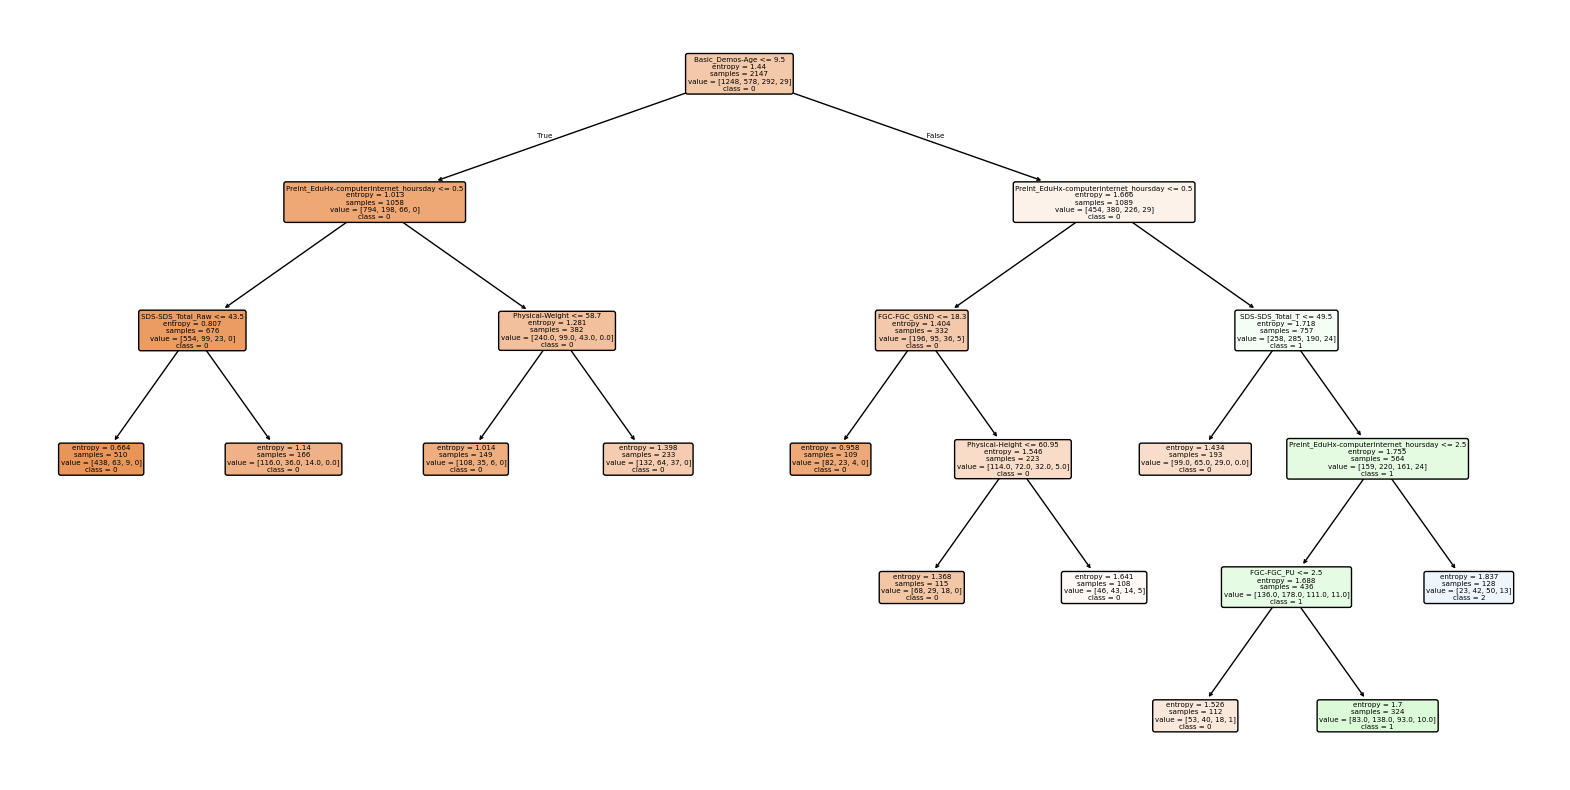

In [182]:
#
# Mostro l'albero di decisione che si va' a crearea usando il valore di alpha ideale
#

plt.figure(figsize=(20,10))
plot_tree(pruned_dt, filled=True, rounded=True, feature_names=X.columns, class_names=["0", "1", "2", "3"])
plt.show()

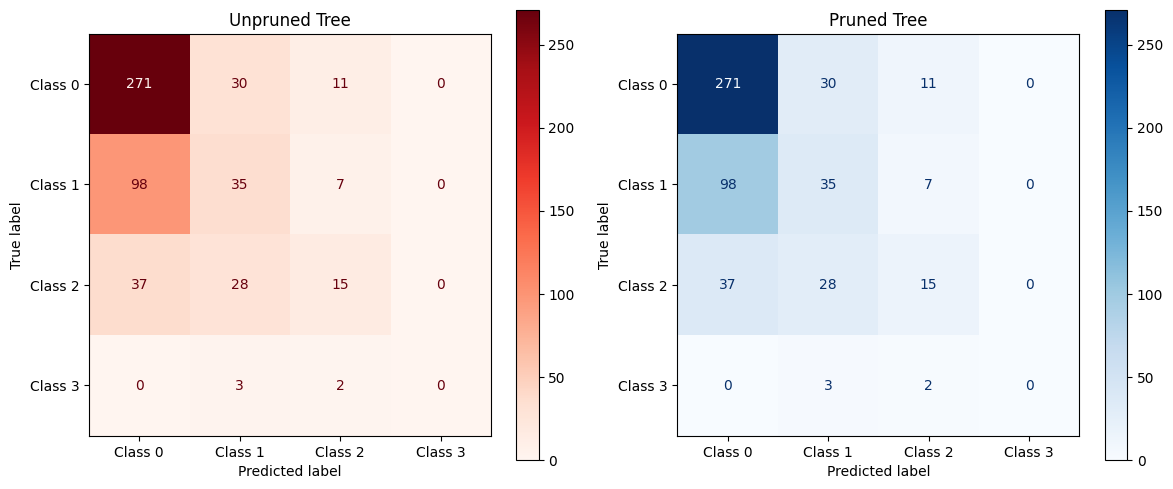

In [183]:
# Mostra la matrice di confusione con etichette
cm_unpruned = confusion_matrix(y_test20, tuned_dt.predict(X_test20))
cm_pruned = confusion_matrix(y_test20, pruned_dt.predict(X_test20))

# Confusion Matrix dei 2 modelli
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
disp_unpruned = ConfusionMatrixDisplay(confusion_matrix=cm_unpruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_unpruned.plot(ax=axes[0], cmap="Reds")
axes[0].set_title("Unpruned Tree")

disp_pruned = ConfusionMatrixDisplay(confusion_matrix=cm_pruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_pruned.plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Pruned Tree")

plt.tight_layout()
plt.show()

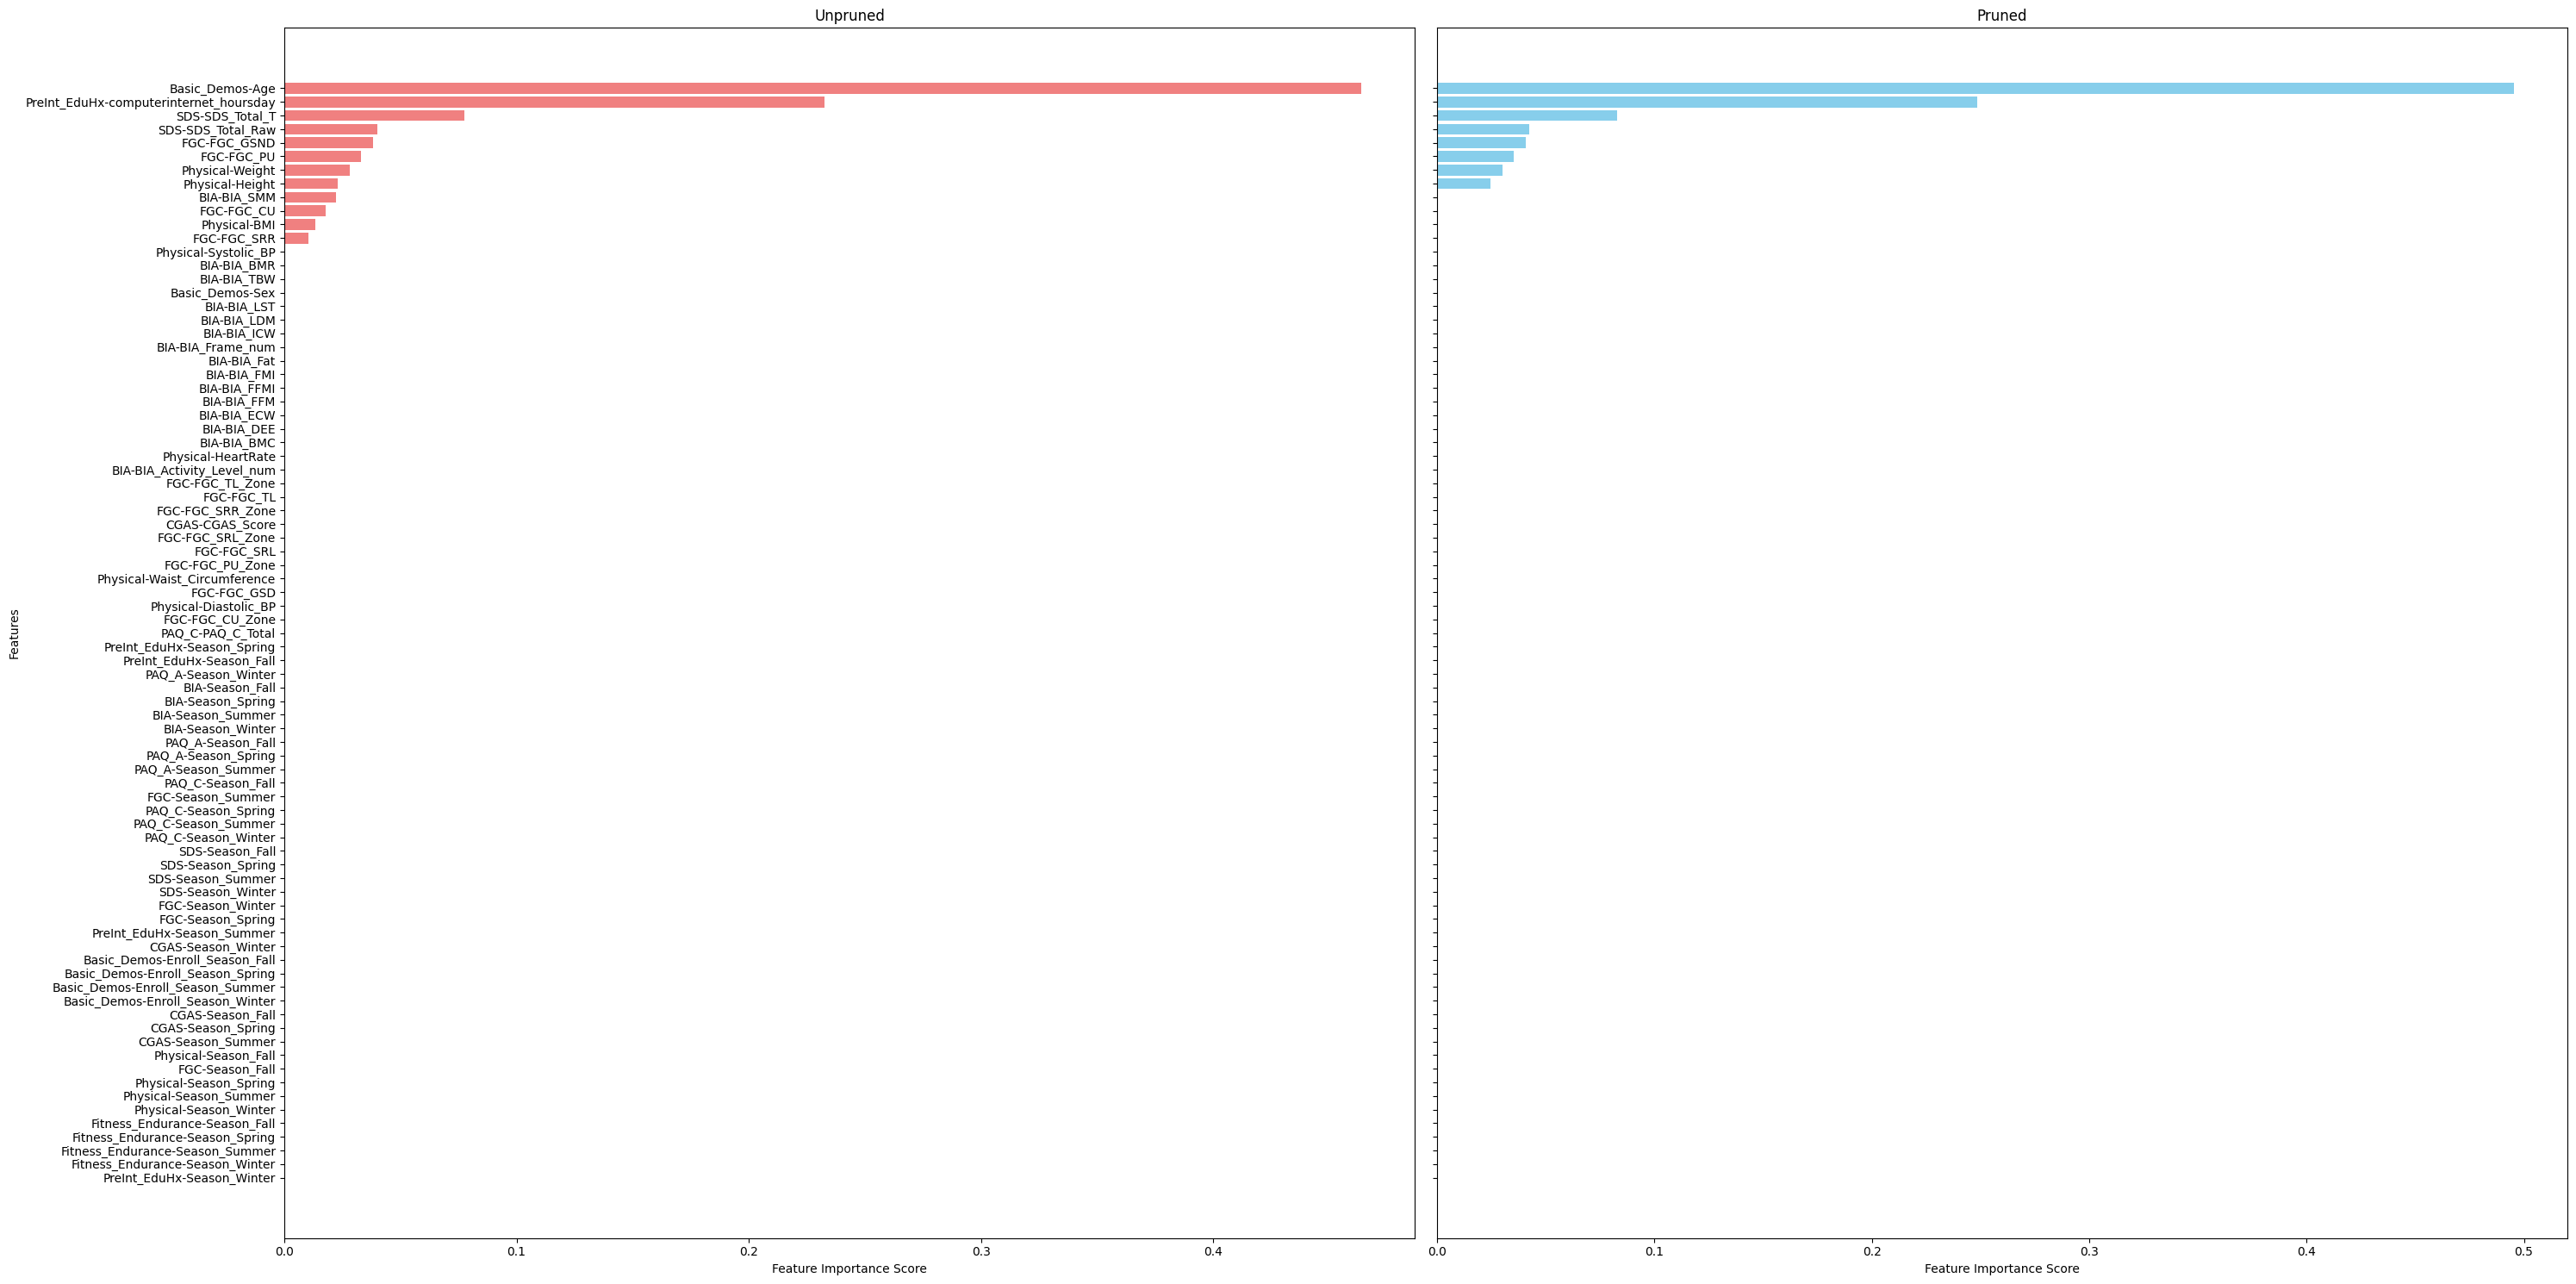

In [184]:
importances_unpruned = tuned_dt.feature_importances_
importances_pruned = pruned_dt.feature_importances_

sorted_idx_unpruned = np.argsort(importances_unpruned)[::-1]
sorted_idx_pruned = np.argsort(importances_pruned)[::-1]
sorted_features_unpruned = X_train80.columns[sorted_idx_unpruned]
sorted_features_pruned = X_train80.columns[sorted_idx_pruned]

fig, axes = plt.subplots(1, 2, figsize=(30, 15), sharey=True)

axes[0].barh(sorted_features_unpruned, importances_unpruned[sorted_idx_unpruned], color='lightcoral')
axes[0].set_xlabel("Feature Importance Score")
axes[0].set_ylabel("Features")
axes[0].set_title("Unpruned")
axes[0].invert_yaxis()

# Pruned tree plot
axes[1].barh(sorted_features_pruned, importances_pruned[sorted_idx_pruned], color='skyblue')
axes[1].set_xlabel("Feature Importance Score")
axes[1].set_title("Pruned")

plt.tight_layout()
plt.show()

Numero ottimale di feature: 6


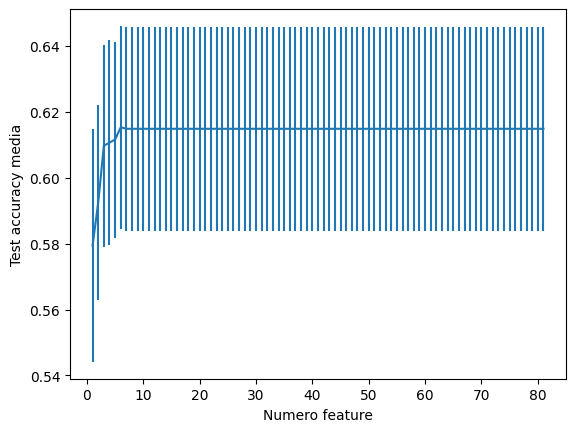

In [185]:
rfecv = RFECV(
    estimator=pruned_dt,
    step=1,
    cv=5,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=2,
)
rfecv.fit(X_train80, y_train80)

print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(
    x=cv_results["n_features"],
    y=cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
)
plt.show()

In [186]:
selected_features = X.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features))

X_train_rfecv = X_train80[selected_features]
X_test_rfecv = X_test20[selected_features]

rfecv_dt = DecisionTreeClassifier(
        **best_params_grid,
        random_state=42 )
rfecv_dt.fit(X_train_rfecv, y_train80)

cv_scores = cross_val_score(rfecv_dt, X_train_rfecv, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Physical-Weight', 'FGC-FGC_GSND', 'FGC-FGC_PU', 'SDS-SDS_Total_Raw', 'PreInt_EduHx-computerinternet_hoursday']
Accuratezza media con cross-validation: 0.6185 ± 0.0296


In [109]:
maxScore = -1
bestEstimators = -1
for i in range(1, 31):
   base_dt = DecisionTreeClassifier(**best_params_grid, ccp_alpha=ideal_alpha, random_state=42)
   dt = BaggingClassifier(estimator=base_dt, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(dt, X_train_rfecv, y_train80, cv=20, scoring='accuracy')
   mean_cv_score = cv_scores.mean()
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i

bagged_dt = BaggingClassifier(estimator=rfecv_dt, n_estimators=bestEstimators, random_state=42)
bagged_dt.fit(X_train_rfecv, y_train80)

print("bestEstimators:", bestEstimators)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bagged_dt.predict(X_test_rfecv))))

cv_scores = cross_val_score(bagged_dt, X_train_rfecv, y_train80, cv=20, scoring='accuracy')

print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")

bestEstimators: 5
Accuracy: 0.592
Accuracy media: 0.611509172724126
Standard Deviation: 0.03545170680538183


Error/Bias/Variance at the last iteration: [0.65633147 0.58691341 0.06941806]


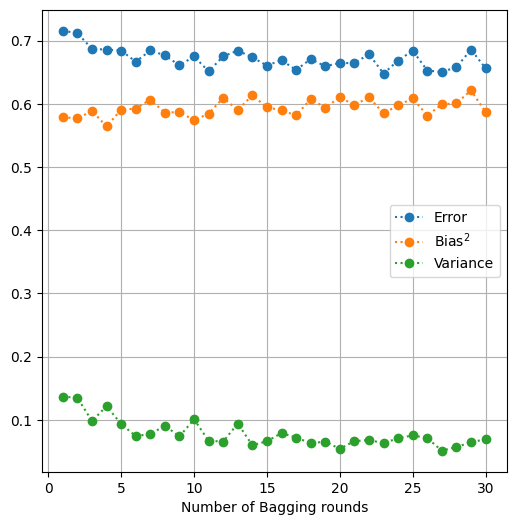

In [29]:
N_TESTS = 20
stats = np.array([])
bags = range(1,31)
for l in bags:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train_rfecv, y_train80, n_samples=int(0.67*len(y_train80)) )

        base_dt = DecisionTreeClassifier(**best_params_grid, ccp_alpha=ideal_alpha, random_state=42)
        bagged_dt = BaggingClassifier(estimator=base_dt, n_estimators=l, random_state=42)
        bagged_dt.fit(Xs,ys)
        
        y_pred = bagged_dt.predict(X_test_rfecv)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20-np.mean(y_preds,axis=1))**2
    dt_variance = np.var(y_preds,axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats

fig, ax = plt.subplots(figsize=(6,6))

ax.plot(bags,stats[0,:], 'o:', label='Error')
ax.plot(bags,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(bags,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Bagging rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [110]:
maxScore = -1
bestEstimators = -1
for i in [1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]:
   base_dt = DecisionTreeClassifier(**best_params_grid, ccp_alpha=ideal_alpha, random_state=42)
   dt = AdaBoostClassifier(estimator=base_dt, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(dt, X_train_rfecv, y_train80, cv=20, scoring='accuracy')
   mean_cv_score = cv_scores.mean()
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i

boosted_dt = AdaBoostClassifier(estimator=rfecv_dt, n_estimators=bestEstimators, random_state=42)
boosted_dt.fit(X_train_rfecv, y_train80)

print("bestEstimators:", bestEstimators)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=boosted_dt.predict(X_test_rfecv))))

cv_scores = cross_val_score(boosted_dt, X_train_rfecv, y_train80, cv=20, scoring='accuracy')

print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")

bestEstimators: 1
Accuracy: 0.598
Accuracy media: 0.618509865005192
Standard Deviation: 0.029550797755029615


Error/Bias/Variance at the last iteration: [0.77020484 0.50456238 0.26564246]


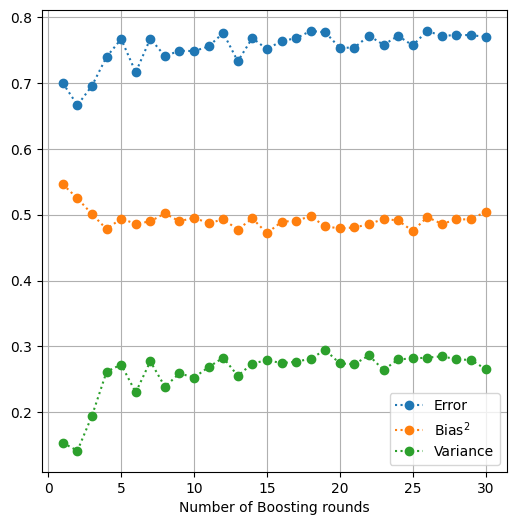

In [31]:
N_TESTS = 20
stats = np.array([])
boosts = range(1,31)
for l in boosts:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train_rfecv, y_train80, n_samples=int(0.67*len(y_train80)) )

        base_dt = DecisionTreeClassifier(**best_params_grid, ccp_alpha=ideal_alpha, random_state=42)
        boosted_dt = AdaBoostClassifier(estimator=base_dt, n_estimators=l, random_state=42)
        boosted_dt.fit(Xs,ys)
        
        y_pred = boosted_dt.predict(X_test_rfecv)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias = (y_test20 - np.mean(y_preds, axis=1))**2
    dt_variance = np.var(y_preds, axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1,1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats
    
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(boosts,stats[0,:], 'o:', label='Error')
ax.plot(boosts,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(boosts,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Boosting rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [187]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train80, y_train80)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=rf.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=rf.predict(X_test20)))

cv_scores = cross_val_score(rf, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

train acc: 1.0
test acc: 0.5884543761638734
CV Accuracy: 0.590 ± 0.033


In [188]:
param_grid = {
    'n_estimators': [100, 150, 200],
    'min_samples_leaf': [10, 15, 20],
    'max_depth': [5, 7, 10],
    'min_impurity_decrease': [0.0, 0.001, 0.003],
}

rf = RandomForestClassifier(random_state=42)
grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, n_jobs=-1, verbose=0, scoring='accuracy')
grid_search_rf.fit(X_train80, y_train80)
print("Best Parameters:", grid_search_rf.best_params_)

tuned_rf = grid_search_rf.best_estimator_

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_rf.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_rf.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_rf, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_rf.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Best Parameters: {'max_depth': 10, 'min_impurity_decrease': 0.001, 'min_samples_leaf': 20, 'n_estimators': 200}
Train Accuracy: 0.672
Test Accuracy: 0.585
Cross-Validation Accuracy: 0.6110 ± 0.0321
Basic_Demos-Age                           0.104354
PreInt_EduHx-computerinternet_hoursday    0.099977
Physical-Height                           0.083154
Physical-Weight                           0.052150
SDS-SDS_Total_Raw                         0.051112
SDS-SDS_Total_T                           0.049653
FGC-FGC_CU                                0.039551
BIA-BIA_LDM                               0.038366
BIA-BIA_SMM                               0.031998
BIA-BIA_LST                               0.030783
dtype: float64


Numero ottimale di feature: 39


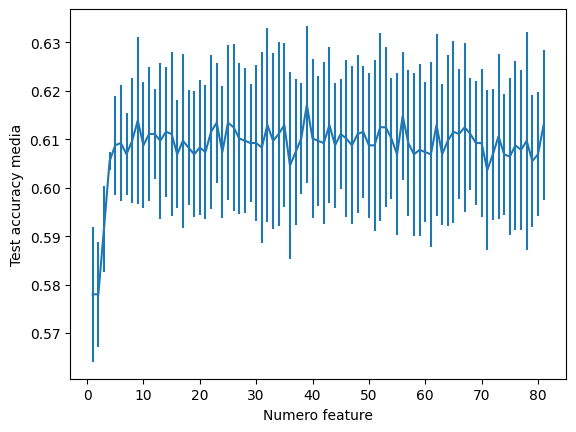

In [189]:
base_rf = RandomForestClassifier(**grid_search_rf.best_params_, random_state=42)
rfecv = RFECV(
    estimator=base_rf,
    step=1,
    cv=5,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)
print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(
    x=cv_results["n_features"],
    y=cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
)
plt.show()

In [190]:
selected_features = X_train80.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features))

X_train_rfecv = X_train80[selected_features]
X_test_rfecv = X_test20[selected_features]

rfecv_rf = RandomForestClassifier(**grid_search_rf.best_params_, random_state=42 )
rfecv_rf.fit(X_train_rfecv, y_train80)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_rf.predict(X_train_rfecv)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_rf.predict(X_test_rfecv)))

cv_scores = cross_val_score(rfecv_rf, X_train_rfecv, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Basic_Demos-Sex', 'CGAS-CGAS_Score', 'Physical-BMI', 'Physical-Height', 'Physical-Weight', 'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP', 'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND', 'FGC-FGC_GSD', 'FGC-FGC_PU', 'FGC-FGC_SRL', 'FGC-FGC_SRR', 'FGC-FGC_SRR_Zone', 'FGC-FGC_TL', 'BIA-BIA_BMC', 'BIA-BIA_BMR', 'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM', 'BIA-BIA_FFMI', 'BIA-BIA_FMI', 'BIA-BIA_Fat', 'BIA-BIA_ICW', 'BIA-BIA_LDM', 'BIA-BIA_LST', 'BIA-BIA_SMM', 'BIA-BIA_TBW', 'PAQ_C-PAQ_C_Total', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T', 'PreInt_EduHx-computerinternet_hoursday', 'Physical-Season_Winter', 'FGC-Season_Spring', 'PAQ_C-Season_Spring', 'SDS-Season_Winter']
Train accuracy: 0.6688402421984164
Test accuracy: 0.5828677839851024
Accuratezza media con cross-validation: 0.6138 ± 0.0321


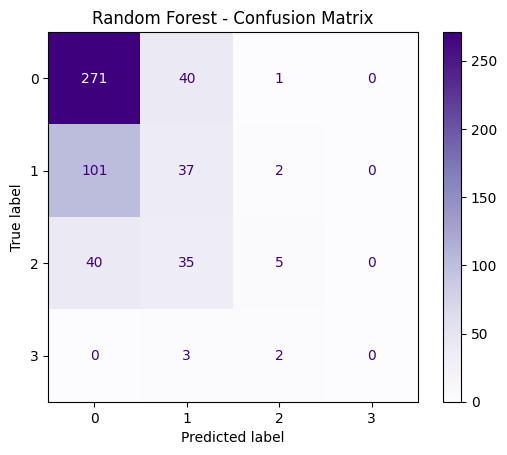

In [191]:
cm = confusion_matrix(y_test20, rfecv_rf.predict(X_test_rfecv))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Purples)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [199]:
df_with_na = df_with_na.astype(float)
df_with_na = df_with_na.round(2)

X = df_with_na.drop(columns=['sii'])
y = df_with_na['sii']

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)

In [201]:
xgBoost = XGBClassifier()
xgBoost.fit(X_train80, y_train80)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=xgBoost.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=xgBoost.predict(X_test20)))

cv_scores = cross_val_score(xgBoost, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

train acc: 1.0
test acc: 0.5716945996275605
CV Accuracy: 0.585 ± 0.043


In [202]:
space={'max_depth': hp.quniform("max_depth", 3, 18, 1),
        'gamma': hp.uniform ('gamma', 0,10),
        'reg_alpha' : hp.quniform('reg_alpha', 0,200,1),
        'reg_lambda' : hp.uniform('reg_lambda', 0,5),
        'colsample_bytree' : hp.uniform('colsample_bytree', 0.5,1),
        'min_child_weight' : hp.quniform('min_child_weight', 0, 10, 1),
        'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.3)),
        'subsample': hp.uniform('subsample', 0.5, 1),
        'n_estimators': hp.quniform('n_estimators', 50, 500, 50),
    }

# Funzione obiettivo per ottimizzare
def objective(space):
    clf=XGBClassifier(max_depth = int(space['max_depth']), 
                      gamma = float(space['gamma']),
                      reg_alpha = float(space['reg_alpha']),
                      reg_lambda=float(space['reg_lambda']),
                      colsample_bytree=float(space['colsample_bytree']),
                      min_child_weight=int(space['min_child_weight']),
                      learning_rate=float(space['learning_rate']),
                      subsample=float(space['subsample']),
                      n_estimators=int(space['n_estimators']))
    
    evaluation = [( X_train80, y_train80), ( X_test20, y_test20)]
    clf.fit(X_train80, y_train80,
            eval_set=[(X_test20, y_test20)],
            verbose=False)

    pred = clf.predict(X_test20)
    accuracy = accuracy_score(y_test20, pred>0.5)
    return {'loss': -accuracy, 'status': STATUS_OK }


trials = Trials()
best_hyperparams = fmin(fn = objective,
                        space = space,
                        algo = tpe.suggest,
                        max_evals = 200,
                        trials = trials)

print("The best hyperparameters are : ","\n")
print(best_hyperparams)

100%|██████████| 200/200 [02:12<00:00,  1.51trial/s, best loss: -0.5940409683426443]
The best hyperparameters are :  

{'colsample_bytree': np.float64(0.6449773325226918), 'gamma': np.float64(9.95678823549853), 'learning_rate': np.float64(0.07619990944661084), 'max_depth': np.float64(18.0), 'min_child_weight': np.float64(9.0), 'n_estimators': np.float64(450.0), 'reg_alpha': np.float64(4.0), 'reg_lambda': np.float64(2.053769903278278), 'subsample': np.float64(0.8904488914663748)}


In [205]:
tuned_xgb = XGBClassifier(
    colsample_bytree=0.6449773325226918,
    gamma=9.95678823549853,
    learning_rate=0.07619990944661084,
    max_depth=int(18.0),
    min_child_weight=int(9.0),
    reg_alpha=4.0,
    reg_lambda=2.053769903278278,
    n_estimators=450, 
    subsample=0.8904488914663748,
    random_state=42
)

tuned_xgb.fit(
    X_train80, y_train80,
    eval_set=[(X_test20, y_test20)],
    verbose=False
)

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_xgb.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_xgb.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_xgb, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_xgb.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Train Accuracy: 0.619
Test Accuracy: 0.587
Cross-Validation Accuracy: 0.6087 ± 0.0289
Basic_Demos-Age                           0.212071
PreInt_EduHx-computerinternet_hoursday    0.123133
Physical-Height                           0.097230
FGC-FGC_GSD                               0.083335
SDS-SDS_Total_T                           0.076677
FGC-FGC_PU                                0.076276
FGC-FGC_CU                                0.072552
SDS-SDS_Total_Raw                         0.072084
Physical-Weight                           0.068419
BIA-BIA_LDM                               0.059967
dtype: float32


Numero ottimale di feature: 57


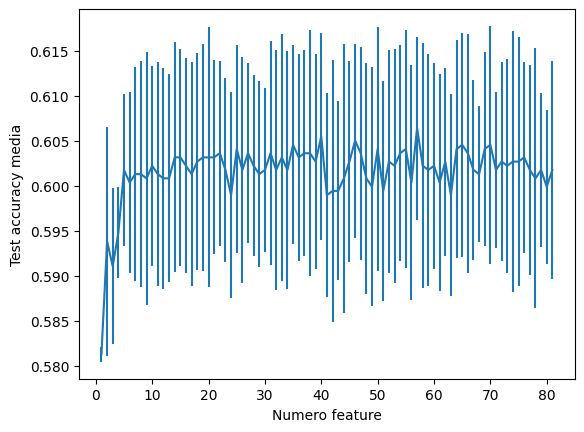

In [206]:
base_xgb = XGBClassifier(
    colsample_bytree=0.6449773325226918,
    gamma=9.95678823549853,
    learning_rate=0.07619990944661084,
    max_depth=int(18.0),
    min_child_weight=int(9.0),
    reg_alpha=4.0,
    reg_lambda=2.053769903278278,
    n_estimators=450, 
    subsample=0.8904488914663748,
    random_state=42
)

rfecv = RFECV(
    estimator=base_xgb,
    step=1,
    cv=5,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)
print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(
    x=cv_results["n_features"],
    y=cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
)
plt.show()

In [207]:
selected_features = X_train80.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features))

X_train_rfecv = X_train80[selected_features]
X_test_rfecv = X_test20[selected_features]

rfecv_xgb = XGBClassifier(
    colsample_bytree=0.6449773325226918,
    gamma=9.95678823549853,
    learning_rate=0.07619990944661084,
    max_depth=int(18.0),
    min_child_weight=int(9.0),
    reg_alpha=4.0,
    reg_lambda=2.053769903278278,
    n_estimators=450, 
    subsample=0.8904488914663748,
    random_state=42
)
rfecv_xgb.fit(
    X_train_rfecv, y_train80,
    eval_set=[(X_test_rfecv, y_test20)],
    verbose=False
)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_xgb.predict(X_train_rfecv)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_xgb.predict(X_test_rfecv)))

cv_scores = cross_val_score(rfecv_xgb, X_train_rfecv, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Basic_Demos-Sex', 'CGAS-CGAS_Score', 'Physical-BMI', 'Physical-Height', 'Physical-Weight', 'Physical-Waist_Circumference', 'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP', 'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND', 'FGC-FGC_GSD', 'FGC-FGC_PU', 'FGC-FGC_PU_Zone', 'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR', 'FGC-FGC_SRR_Zone', 'FGC-FGC_TL', 'FGC-FGC_TL_Zone', 'BIA-BIA_Activity_Level_num', 'BIA-BIA_BMC', 'BIA-BIA_BMR', 'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM', 'BIA-BIA_LDM', 'BIA-BIA_SMM', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T', 'PreInt_EduHx-computerinternet_hoursday', 'Basic_Demos-Enroll_Season_Fall', 'Basic_Demos-Enroll_Season_Spring', 'Basic_Demos-Enroll_Season_Summer', 'Basic_Demos-Enroll_Season_Winter', 'CGAS-Season_Fall', 'CGAS-Season_Spring', 'CGAS-Season_Summer', 'CGAS-Season_Winter', 'Physical-Season_Fall', 'Physical-Season_Spring', 'Physical-Season_Summer', 'Physical-Season_Winter', 'Fitness_Enduranc

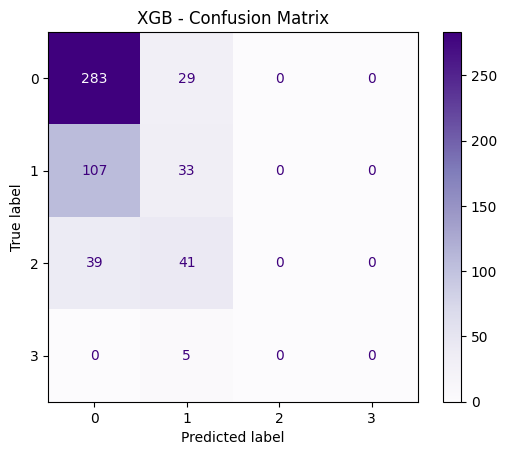

In [208]:
cm = confusion_matrix(y_test20, rfecv_xgb.predict(X_test_rfecv))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Purples)
plt.title("XGB - Confusion Matrix")
plt.show()

In [10]:
X = df_with_cat_and_na.drop(columns=['sii'])
y = df_with_cat_and_na['sii']

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)

for col in season_cols:
    X_train80[col] = X_train80[col].astype(str)
    X_test20[col] = X_test20[col].astype(str)

In [11]:
from catboost import CatBoostClassifier

catBoost = CatBoostClassifier(verbose=False, random_state=42)
catBoost.fit(X_train80, y_train80, cat_features=season_cols)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=catBoost.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=catBoost.predict(X_test20)))


train acc: 0.9296693060083838
test acc: 0.5810055865921788


In [ ]:
from sklearn.metrics import mean_squared_error
import optuna

def check_acc(model,X,y):
    y_pred = model.predict(X)
    return accuracy_score(y, y_pred)

def objective(trial):
  params = {"iterations": 1000,
            "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.1, log=True),
            "depth": trial.suggest_int("depth", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.05, 1.0),
            "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.05, 1.0),
            "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 100),
            "bootstrap_type": "Bernoulli"}
    
  cb = CatBoostClassifier(**params, silent=True, random_state=42)
  cb.fit(X_train80, y_train80,
                eval_set=[(X_test20, y_test20)],
                cat_features=season_cols,
                early_stopping_rounds=100)
  return check_acc(cb, X_test20, y_test20)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, n_jobs=-1)

[I 2025-04-18 13:44:02,755] A new study created in memory with name: no-name-30ee0ad1-3b12-44c4-af47-ef493bf579d3
[I 2025-04-18 13:44:04,320] Trial 4 finished with value: 0.5865921787709497 and parameters: {'learning_rate': 0.09604565985916745, 'depth': 3, 'subsample': 0.7829069761727281, 'colsample_bylevel': 0.19147912117145863, 'min_data_in_leaf': 18}. Best is trial 4 with value: 0.5865921787709497.
[I 2025-04-18 13:44:05,693] Trial 1 finished with value: 0.5865921787709497 and parameters: {'learning_rate': 0.029431713582949298, 'depth': 2, 'subsample': 0.2908718488334141, 'colsample_bylevel': 0.22289786104122933, 'min_data_in_leaf': 13}. Best is trial 4 with value: 0.5865921787709497.
[I 2025-04-18 13:44:06,166] Trial 7 finished with value: 0.5772811918063314 and parameters: {'learning_rate': 0.003280108316028361, 'depth': 1, 'subsample': 0.26032247222901406, 'colsample_bylevel': 0.8893385826796384, 'min_data_in_leaf': 39}. Best is trial 4 with value: 0.5865921787709497.
[I 2025-04-

In [17]:
study.best_value, study.best_params

(0.6033519553072626,
 {'learning_rate': 0.017606819670890735,
  'depth': 7,
  'subsample': 0.9984412345241243,
  'colsample_bylevel': 0.5006176393204117,
  'min_data_in_leaf': 97})

In [55]:
tuned_cat = CatBoostClassifier(
    learning_rate=study.best_params['learning_rate'],
    depth=study.best_params['depth'],
    subsample=study.best_params['subsample'],
    colsample_bylevel=study.best_params['colsample_bylevel'],
    min_data_in_leaf=study.best_params['min_data_in_leaf'],
    bootstrap_type='Bernoulli',
    iterations=8000,
    use_best_model=True,
    eval_metric='Accuracy',
    od_type='iter',
    od_wait=50,
    random_state=42,
    logging_level='Silent',
)

tuned_cat.fit(X_train80, y_train80,
               eval_set=[(X_test20, y_test20)],
               cat_features=season_cols,
               early_stopping_rounds=100)
pred_train = tuned_cat.predict(X_train80)
print(f"Train acc : {check_acc(tuned_cat,X_train80,y_train80)}")
print(f"Test acc : {check_acc(tuned_cat,X_test20,y_test20)}")

feature_importances = tuned_cat.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Train acc : 0.6176059618071728
Test acc : 0.5921787709497207
PreInt_EduHx-computerinternet_hoursday    38.781322
Basic_Demos-Age                           12.259452
BIA-BIA_TBW                                9.907845
Fitness_Endurance-Season                   5.282274
FGC-FGC_SRR_Zone                           5.129375
FGC-FGC_PU                                 4.825205
BIA-BIA_BMC                                4.001041
PAQ_C-PAQ_C_Total                          3.990868
BIA-BIA_ICW                                3.760643
BIA-BIA_LDM                                3.114462
dtype: float64
